# Practical No. 02: Text Classification using Embedding Layer and LSTM

## Aim
Build a **text classification model** for a **binary classification** task (positive vs. negative movie-review sentences) using an **Embedding layer** and an **LSTM network**, and evaluate it using appropriate classification metrics.

## Theory (short)
| Component | Role |
|---|---|
| **Tokenizer** | Converts each word into an integer index. |
| **Padding** | Makes every review the same length so they can be batched. |
| **Embedding layer** | Learns a dense vector (e.g. 64-dim) for every word; similar words get similar vectors. |
| **LSTM** | Reads the embedded sequence word by word and keeps a memory (cell state), so it can capture word order and long-range context. |
| **Dense (sigmoid)** | Outputs the probability that the review is positive. |

**Pipeline:** Raw text → Clean → Tokenize → Pad → Embedding → LSTM → Dense(sigmoid) → Probability → Class

**Dataset:** NLTK *Sentence Polarity* corpus (Pang & Lee movie-review snippets): **10,662 sentences**, 5,331 positive and 5,331 negative.

## Step 1: Import Libraries

In [1]:
import re, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

import nltk
from nltk.corpus import sentence_polarity

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix,
                             roc_curve, roc_auc_score)

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

I0000 00:00:1791879225.340933     385 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791879225.408296     385 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791879227.187297     385 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


## Step 2: Load the Dataset
We download the NLTK sentence-polarity corpus and build a DataFrame with two columns: `text` and `label` (1 = positive, 0 = negative).

In [2]:
nltk.download("sentence_polarity", quiet=True)

texts, labels = [], []
for cat, lab in [("pos", 1), ("neg", 0)]:
    for sent in sentence_polarity.sents(categories=cat):
        texts.append(" ".join(sent))
        labels.append(lab)

df = pd.DataFrame({"text": texts, "label": labels})
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)   # shuffle

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10662, 2)


,text,label
0,"a dark , dull thriller with a parting shot tha...",0
1,director chris eyre is going through the paces...,0
2,"although it lacks the detail of the book , the...",1
3,the script by david koepp is perfectly service...,1
4,"an exciting and involving rock music doc , a s...",1


## Step 3: Exploratory Data Analysis (EDA)
Check the class balance and review lengths. Review length helps us choose a sensible padding length.

Class distribution:
 label
Negative    5331
Positive    5331
Name: count, dtype: int64

Sentence length (words) summary:
 count    10662.0
mean        21.0
std          9.4
min          1.0
25%         14.0
50%         20.0
75%         27.0
max         59.0
Name: n_words, dtype: float64


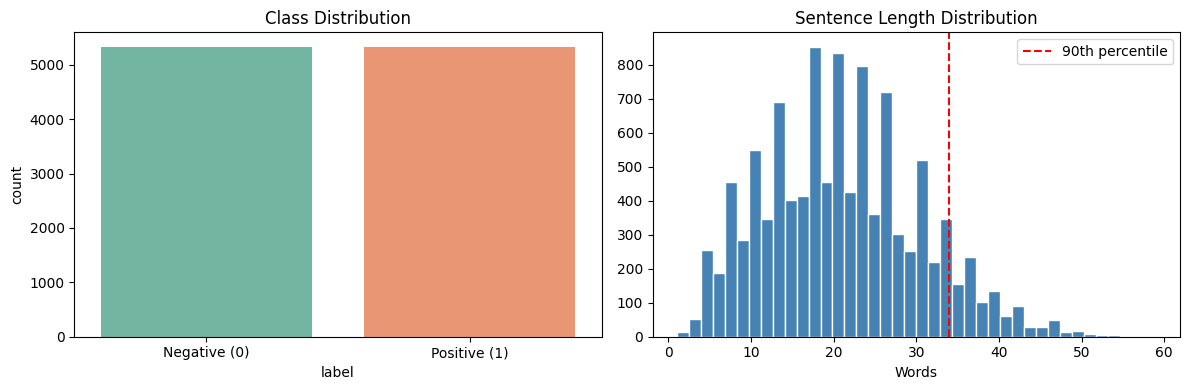

In [3]:
df["n_words"] = df["text"].apply(lambda t: len(t.split()))

print("Class distribution:\n", df["label"].value_counts().rename({1: "Positive", 0: "Negative"}))
print("\nSentence length (words) summary:\n", df["n_words"].describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="label", data=df, ax=ax[0], palette="Set2")
ax[0].set_xticklabels(["Negative (0)", "Positive (1)"]); ax[0].set_title("Class Distribution")
ax[1].hist(df["n_words"], bins=40, color="steelblue", edgecolor="white")
ax[1].axvline(df["n_words"].quantile(0.9), color="red", ls="--", label="90th percentile")
ax[1].set_title("Sentence Length Distribution"); ax[1].set_xlabel("Words"); ax[1].legend()
plt.tight_layout(); plt.show()

**Observation:** The dataset is perfectly balanced, so *accuracy* is a fair metric (we will still report precision, recall, F1 and ROC-AUC). Most sentences are under ~40 words, so a padding length of 40 covers almost all of them.

## Step 4: Text Cleaning
Lower-case the text, remove non-alphabetic characters and extra spaces.

In [4]:
def clean_text(t):
    t = t.lower()
    t = re.sub(r"[^a-z\s]", " ", t)       # keep only letters
    t = re.sub(r"\s+", " ", t).strip()    # collapse spaces
    return t

df["clean"] = df["text"].apply(clean_text)

print("BEFORE:", df["text"][0][:200].replace("\n", " "))
print("\nAFTER :", df["clean"][0][:200])

BEFORE: a dark , dull thriller with a parting shot that misfires .

AFTER : a dark dull thriller with a parting shot that misfires


## Step 5: Train / Validation / Test Split
We use **70% train, 15% validation, 15% test**, stratified so each split has equal class proportions.

In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    df["clean"], df["label"], test_size=0.30, stratify=df["label"], random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print("Train :", X_train.shape[0], "| Val :", X_val.shape[0], "| Test :", X_test.shape[0])

Train : 7463 | Val : 1599 | Test : 1600


## Step 6: Tokenization and Padding
* `Tokenizer(num_words=VOCAB_SIZE)` keeps only the most frequent words; rare words map to `<OOV>`.
* The tokenizer is **fit only on training data** to avoid data leakage.
* `pad_sequences` pads/truncates every sentence to `MAX_LEN` tokens.

In [6]:
VOCAB_SIZE = 8000      # size of vocabulary
MAX_LEN    = 40        # words kept per sentence
EMBED_DIM  = 64        # size of each word vector

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

def to_padded(texts):
    seq = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seq, maxlen=MAX_LEN, padding="pre", truncating="pre")

Xtr, Xv, Xte = to_padded(X_train), to_padded(X_val), to_padded(X_test)
ytr, yv, yte = y_train.values, y_val.values, y_test.values

print("Unique words found in training data:", len(tokenizer.word_index))
print("Padded training shape:", Xtr.shape)
print("\nExample review (first 20 tokens):", Xtr[0][:20])
print("Decoded back            :", " ".join(tokenizer.index_word.get(i, "") for i in Xtr[0][:20]))

Unique words found in training data: 15286
Padded training shape: (7463, 40)

Example review (first 20 tokens): [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Decoded back            :                    


## Step 7: Build the Model (Embedding + LSTM)

| Layer | Purpose |
|---|---|
| `Embedding(8000, 64)` | Maps each word index to a learnable 64-d vector. `mask_zero=True` makes the LSTM ignore padding. |
| `SpatialDropout1D(0.3)` | Drops whole embedding dimensions to regularise the embeddings. |
| `LSTM(64)` | Reads the 40-word sequence and outputs a 64-d summary of the sentence. |
| `Dropout(0.5)` | Randomly drops units to reduce overfitting. |
| `Dense(32, relu)` | Hidden layer for learning combinations of LSTM features. |
| `Dense(1, sigmoid)` | Output: probability of the sentence being *positive*. |

In [7]:
model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM, mask_zero=True),
    SpatialDropout1D(0.3),
    LSTM(64),
    Dropout(0.4),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.build(input_shape=(None, MAX_LEN))
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
              loss="binary_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 40, 64)         │       512,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 40, 64)         │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 547,137 (2.09 MB)

 Trainable params: 547,137 (2.09 MB)

 Non-trainable params: 0 (0.00 B)

## Step 8: Train the Model
* **Loss:** binary cross-entropy (binary task).
* **EarlyStopping:** stops training when validation accuracy stops improving and restores the best weights, which prevents overfitting.

In [8]:
early_stop = EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True, verbose=1)

history = model.fit(Xtr, ytr,
                    validation_data=(Xv, yv),
                    epochs=20,
                    batch_size=64,
                    callbacks=[early_stop],
                    verbose=2)

Epoch 1/20


E0000 00:00:1791879231.654555     385 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


117/117 - 8s - 65ms/step - accuracy: 0.5446 - loss: 0.6896 - val_accuracy: 0.6323 - val_loss: 0.6669


Epoch 2/20


117/117 - 5s - 41ms/step - accuracy: 0.7347 - loss: 0.5607 - val_accuracy: 0.7311 - val_loss: 0.5404


...

117/117 - 10s - 83ms/step - accuracy: 0.9417 - loss: 0.1736 - val_accuracy: 0.7405 - val_loss: 0.8112


Epoch 6/20


117/117 - 6s - 48ms/step - accuracy: 0.9443 - loss: 0.1539 - val_accuracy: 0.7361 - val_loss: 0.7832


Epoch 6: early stopping


Restoring model weights from the end of the best epoch: 3.


## Step 9: Training Curves
Plot accuracy and loss for train vs. validation to check for over/under-fitting.

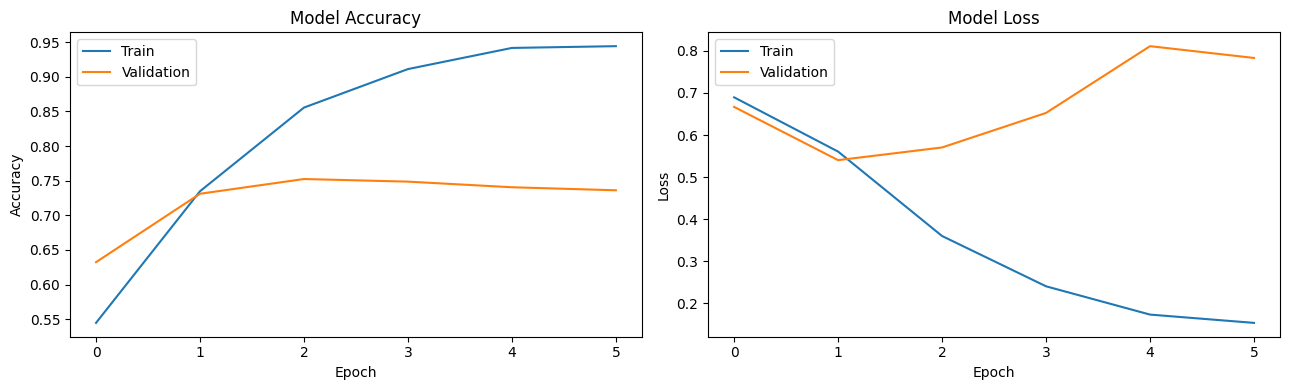

In [9]:
hist = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist["accuracy"], label="Train"); ax[0].plot(hist["val_accuracy"], label="Validation")
ax[0].set_title("Model Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].legend()
ax[1].plot(hist["loss"], label="Train"); ax[1].plot(hist["val_loss"], label="Validation")
ax[1].set_title("Model Loss"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].legend()
plt.tight_layout(); plt.show()

## Step 10: Evaluate on the Test Set
The test set was never used in training or validation, so it gives an honest estimate of performance.
We convert predicted probabilities to classes using a **0.5 threshold**.

In [10]:
test_loss, test_acc = model.evaluate(Xte, yte, verbose=0)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f}")

y_prob = model.predict(Xte, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

Test Loss     : 0.5293
Test Accuracy : 0.7675


### 10.1 Accuracy, Precision, Recall, F1-score

In [11]:
metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Value":  [accuracy_score(yte, y_pred), precision_score(yte, y_pred),
               recall_score(yte, y_pred),   f1_score(yte, y_pred),
               roc_auc_score(yte, y_prob)]
}).round(4)
metrics

,Metric,Value
0,Accuracy,0.7675
1,Precision,0.7737
2,Recall,0.7562
3,F1-score,0.7649
4,ROC-AUC,0.8388


### 10.2 Classification Report (per class)

In [12]:
print(classification_report(yte, y_pred, target_names=["Negative", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.7616    0.7788    0.7701       800
    Positive     0.7737    0.7562    0.7649       800

    accuracy                         0.7675      1600
   macro avg     0.7676    0.7675    0.7675      1600
weighted avg     0.7676    0.7675    0.7675      1600



### 10.3 Confusion Matrix
Rows = actual class, columns = predicted class. Diagonal cells are correct predictions.

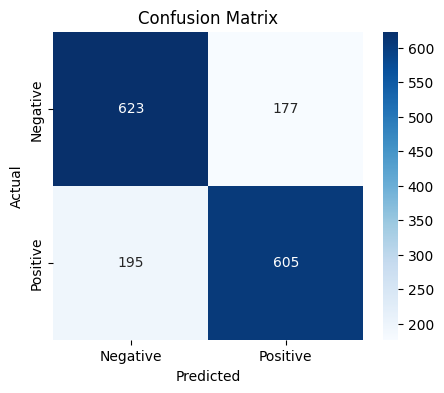

True Negatives : 623   False Positives: 177
False Negatives: 195   True Positives : 605


In [13]:
cm = confusion_matrix(yte, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives : {tn}   False Positives: {fp}")
print(f"False Negatives: {fn}   True Positives : {tp}")

### 10.4 ROC Curve
The ROC curve shows the trade-off between true-positive rate and false-positive rate across all thresholds. AUC close to 1 is better; 0.5 is random guessing.

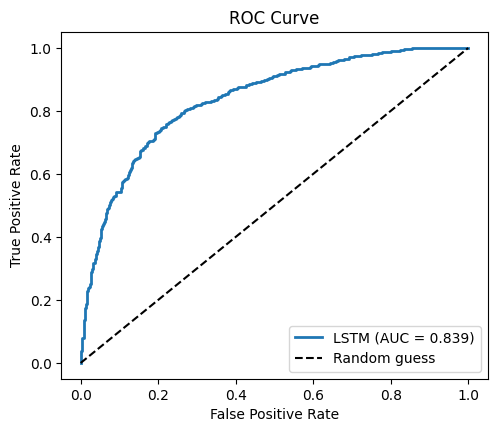

In [14]:
fpr, tpr, _ = roc_curve(yte, y_prob)
auc = roc_auc_score(yte, y_prob)
plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr, tpr, lw=2, label=f"LSTM (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend(); plt.show()

## Step 11: Predict on New (Custom) Reviews
We pass new sentences through the same pipeline: clean → tokenize → pad → predict.

In [15]:
def predict_sentiment(review):
    seq = pad_sequences(tokenizer.texts_to_sequences([clean_text(review)]),
                        maxlen=MAX_LEN, padding="pre", truncating="pre")
    p = float(model.predict(seq, verbose=0)[0][0])
    return ("Positive" if p >= 0.5 else "Negative"), p

samples = [
    "An absolutely brilliant film with wonderful acting and a moving story. I loved every minute of it.",
    "A boring, predictable mess. The plot made no sense and the acting was terrible. Waste of time.",
    "The movie had great visuals but the script was weak and the ending disappointing.",
]
for s in samples:
    label, p = predict_sentiment(s)
    print(f"Review    : {s}\nPrediction: {label}  (P(positive) = {p:.3f})\n")

Review    : An absolutely brilliant film with wonderful acting and a moving story. I loved every minute of it.
Prediction: Positive  (P(positive) = 0.999)

Review    : A boring, predictable mess. The plot made no sense and the acting was terrible. Waste of time.
Prediction: Negative  (P(positive) = 0.007)

Review    : The movie had great visuals but the script was weak and the ending disappointing.
Prediction: Negative  (P(positive) = 0.047)



## Step 12: Conclusion
* A text classifier was built using **Embedding → LSTM → Dense(sigmoid)** for binary sentiment classification.
* Text was cleaned, tokenized (vocabulary of 8,000) and padded to 40 tokens; the Embedding layer learned 64-dimensional word vectors.
* **EarlyStopping** controlled overfitting; training/validation curves were used to monitor it.
* The model was evaluated on unseen test data using **Accuracy, Precision, Recall, F1-score, Confusion Matrix and ROC-AUC**.
* The dataset is small (10,662 short sentences), so performance is limited. Accuracy can be improved with a larger dataset (e.g. IMDB 50k), pre-trained embeddings (GloVe / Word2Vec), a Bidirectional LSTM or GRU, and hyper-parameter tuning.

**Result:** The Embedding + LSTM model was successfully implemented and evaluated for text classification.